In [10]:
import os
import geopandas as gpd
import matplotlib.pyplot as plt
from preprocess import process_event
import rasterio
from pathlib import Path
import geopandas as gpd
from shapely.geometry import shape, box
import json
import re
from datetime import datetime

# Configura la visualización
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 10)

In [2]:
# Cell 2: Rutas de archivos
adiyaman_gpkg = r"E:\Sauvageduck24\AIFOREARTHQUAKE\data\international-charter-eo4ai-etq-challenge\Training\Annotations\Call_919_Turkey\adiyaman_training.gpkg"
antakya_gpkg = r"E:\Sauvageduck24\AIFOREARTHQUAKE\data\international-charter-eo4ai-etq-challenge\Training\Annotations\Call_919_Turkey\antakya_east_training.gpkg"

adiyaman_img_dir = r"E:\Sauvageduck24\AIFOREARTHQUAKE\data\international-charter-eo4ai-etq-challenge\Training\Call_919_Turkey"
antakya_img_dir = r"E:\Sauvageduck24\AIFOREARTHQUAKE\data\international-charter-eo4ai-etq-challenge\Training\Call_919_Turkey"

In [ ]:
# Cell 3: Cargar el GeoDataFrame
gdf_adiyaman = gpd.read_file(adiyaman_gpkg)
print(f"Total de geometrías: {len(gdf_adiyaman)}")
gdf_adiyaman.head()

Total de geometrías: 364


,damaged,fid_adiyaman,geometry
0,1,1,"MULTIPOLYGON (((436400.63 4179318.947, 436423...."
1,0,2,"MULTIPOLYGON (((436349.845 4179640.536, 436366..."
2,0,3,"MULTIPOLYGON (((436369.304 4179746.693, 436369..."
3,1,4,"MULTIPOLYGON (((435923.177 4179596.597, 435940..."
4,0,5,"MULTIPOLYGON (((436772.585 4179747.239, 436776..."


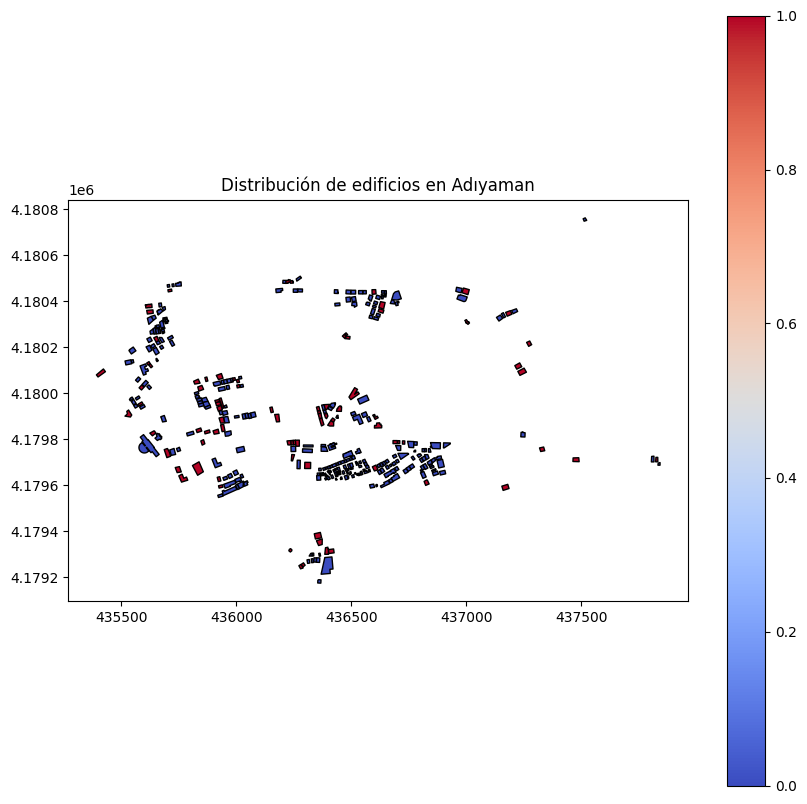

In [ ]:
# Cell 4: Visualizar algunas geometrías
gdf_adiyaman.plot(column='damaged', cmap='coolwarm', legend=True, edgecolor='black')
plt.title("Distribución de edificios en Adıyaman")
plt.show()

In [6]:
# Cell 3: Cargar el GeoDataFrame
gdf_antakya = gpd.read_file(antakya_gpkg)
print(f"Total de geometrías: {len(gdf_antakya)}")
gdf_antakya.head()

Total de geometrías: 705


,damaged,fid_antakya_east,geometry
0,0,1,"MULTIPOLYGON (((36.16499 36.23724, 36.16525 36..."
1,0,2,"MULTIPOLYGON (((36.16568 36.23757, 36.16592 36..."
2,0,3,"MULTIPOLYGON (((36.16198 36.20325, 36.16198 36..."
3,0,4,"MULTIPOLYGON (((36.16234 36.20305, 36.16248 36..."
4,0,6,"MULTIPOLYGON (((36.16194 36.20245, 36.162 36.2..."


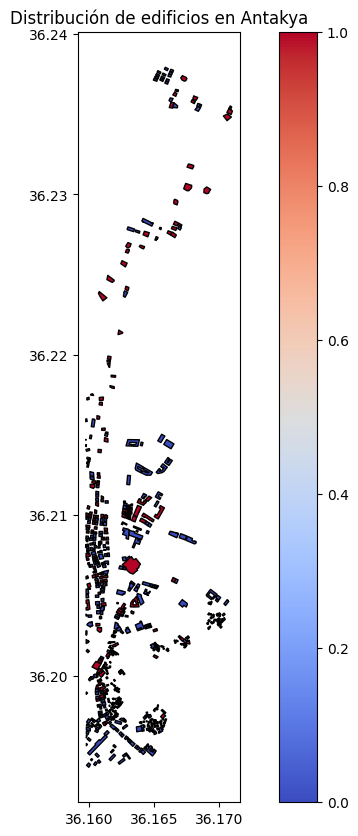

In [8]:
# Cell 4: Visualizar algunas geometrías
gdf_antakya.plot(column='damaged', cmap='coolwarm', legend=True, edgecolor='black')
plt.title("Distribución de edificios en Antakya")
plt.show()

In [11]:
ACTIVATION_DATE = datetime.fromisoformat("2023-02-06")   # Charter Turkey

def extract_date_from_name(name: str) -> datetime | None:
    """
    Extrae la primera cadena AAAAMMDD del nombre de la escena y la convierte a datetime.
    """
    m = re.search(r"(\d{8})", name)
    if m:
        return datetime.strptime(m.group(1), "%Y%m%d")
    return None

In [12]:
def find_tifs_for_gpkg(
    gpkg_path: str | Path,
    training_root: str | Path = r"E:\Sauvageduck24\AIFOREARTHQUAKE\data\international-charter-eo4ai-etq-challenge\Training\Call_919_Turkey",
):
    gpkg_path = Path(gpkg_path)
    training_root = Path(training_root)

    # 1) Cargar geometrías y transformar a WGS-84
    gdf = gpd.read_file(gpkg_path)
    if gdf.crs is None:
        raise ValueError("El .gpkg no tiene CRS definido.")
    gdf = gdf.to_crs(4326)
    aoi = gdf.unary_union          # MultiPolygon de toda el área

    resultados = []                # Lista de dicts a devolver

    # 2) Recorrer todas las escenas *.json bajo *-calibrated
    for item_json in training_root.glob("*-calibrated/*.json"):
        try:
            with open(item_json, "r", encoding="utf-8") as f:
                item = json.load(f)
        except Exception as e:
            print(f"[WARN] No se pudo leer {item_json}: {e}")
            continue

        # 3) Obtener geometría o bbox de la escena
        if "geometry" in item:
            escena_geom = shape(item["geometry"])
        elif "bbox" in item:
            bbox = item["bbox"]     # [xmin, ymin, xmax, ymax]
            escena_geom = box(*bbox)
        else:
            print(f"[WARN] {item_json} sin geometry ni bbox")
            continue

        # 4) ¿Hace solape con el .gpkg?
        if not escena_geom.intersects(aoi):
            continue

        # 5) Identificar TIFFs en Optical_Calibration/
        calib_dir = item_json.parent / "Optical_Calibration"
        tifs = sorted(calib_dir.glob("r-*.tif"))
        if not tifs:
            print(f"[WARN] Sin TIFFs en {calib_dir}")
            continue

        # 6) Fecha de la escena → pre / post
        scene_date = None
        # 6a) STAC property
        scene_date_str = item.get("properties", {}).get("datetime")
        if scene_date_str:
            scene_date = datetime.fromisoformat(scene_date_str.replace("Z", "+00:00"))
        # 6b) o fallback al nombre
        if scene_date is None:
            scene_date = extract_date_from_name(item_json.stem)

        relation = None
        if scene_date:
            relation = "post" if scene_date >= ACTIVATION_DATE else "pre"

        resultados.append(
            dict(
                scene_id=item_json.parent.name,
                scene_date=scene_date.isoformat() if scene_date else "unknown",
                relation=relation,
                item_json=str(item_json),
                tifs=[str(p) for p in tifs],
            )
        )

    return resultados

In [13]:
# Cambia el path al gpkg que quieras analizar:
gpkg = r"E:\Sauvageduck24\AIFOREARTHQUAKE\data\international-charter-eo4ai-etq-challenge\Training\Annotations\Call_919_Turkey\adiyaman_training.gpkg"

matches = find_tifs_for_gpkg(gpkg)
if not matches:
    print("No se encontraron escenas que cubran el AOI.")
else:
    for m in matches:
        print(f"\n=== {m['scene_id']}  ({m['relation']}) ===")
        print(f"Fecha escena : {m['scene_date']}")
        print("TIFFs:")
        for p in m["tifs"]:
            print("   ", p)


C:\Users\esteb\AppData\Local\Temp\ipykernel_9180\3370029003.py:13: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  aoi = gdf.unary_union          # MultiPolygon de toda el área


TypeError: can't compare offset-naive and offset-aware datetimes